# Credit Risk & Loan Default Analysis
**Tools:** SQL (SQLite inside Python), pandas, matplotlib | **Data:** Lending Club, loans issued Apr–Dec 2015

**One-line summary (say this first in the interview):**
*"I analysed 283K resolved Lending Club loans to find which borrowers default, built a simple risk flag on grade and DTI, tested it on unseen months, and showed it removes 40% of defaults while declining 22% of loans."*

### Full forms (learn these)
| Term | Full form / meaning |
|---|---|
| **DTI** | Debt-to-Income ratio: monthly debt payments ÷ monthly income (%). Higher = riskier |
| **FICO** | Fair Isaac Corporation credit score (300–850). Higher = safer |
| **Grade A–G** | Lending Club's own risk rating. A = safest, G = riskiest |
| **Charged Off** | Lender wrote the loan off as a loss (borrower stopped paying). We treat it as **default** |
| **Resolved loan** | Loan with a final outcome: Fully Paid or Charged Off/Default |
| **Default rate** | Defaults ÷ resolved loans |
| **pp** | Percentage points (20.0% → 15.3% is a 4.7 pp fall) |
| **P&L / Return** | Cash received − amount funded; return = P&L ÷ funded amount |
| **SQL / CTE / CASE WHEN** | Structured Query Language / Common Table Expression / if-else inside SQL |

### What the project does (5 steps)
1. **Load** 16 CSV parts (320,000 loans) → 2. **Clean** with SQL (keep resolved loans, drop invalid income/DTI) and build bands → 3. **Segment**: default rate by grade, DTI, income, FICO → 4. **Risk flag** built on Apr–Aug, **tested** on Sep–Dec → 5. **Back-test**: defaults avoided, good loans lost, return of flagged vs approved.

## 1. Setup

In [1]:
import os, glob, re, sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = os.environ.get("LC_DATA_DIR", ".")        # folder that holds the CSV parts
PATTERN  = "*accepted_2007_to_2018Q4_*.csv"            # matches ..._1.csv to ..._16.csv
pd.options.display.float_format = "{:,.2f}".format

## 2. Load the data
`usecols` reads only the 17 columns we need (the raw file has 151), so it loads fast and uses little memory.
If you have the single full file instead of the parts, use `pd.read_csv("accepted_2007_to_2018Q4.csv", nrows=320000, usecols=COLS)`. The first 320,000 rows are exactly these loans.

In [2]:
COLS = ["id","loan_amnt","funded_amnt","term","int_rate","grade","home_ownership","annual_inc",
        "verification_status","issue_d","loan_status","purpose","dti","fico_range_low",
        "total_pymnt","total_rec_prncp","recoveries"]

def load_parts(folder, pattern):
    files = glob.glob(os.path.join(folder, pattern))
    files.sort(key=lambda f: int(re.search(r"_(\d+)\.csv$", f).group(1)))   # order parts 1..16
    frames = (pd.read_csv(f, usecols=COLS, low_memory=False) for f in files)
    return pd.concat(frames, ignore_index=True), len(files)

raw, n_files = load_parts(DATA_DIR, PATTERN)
raw["issue_dt"] = pd.to_datetime(raw["issue_d"], format="%b-%Y")
print(f"{n_files} files | {len(raw):,} loans | issued {raw.issue_dt.min():%b %Y} to {raw.issue_dt.max():%b %Y}")
raw["loan_status"].value_counts()

16 files | 320,000 loans | issued Apr 2015 to Dec 2015


loan_status
Fully Paid            226400
Charged Off            57262
Current                34479
Late (31-120 days)      1127
In Grace Period          505
Late (16-30 days)        226
Default                    1
Name: count, dtype: int64

## 3. Clean with SQL
We load the data into an **in-memory SQLite database** and do the cleaning in SQL.
- Keep only **resolved** loans (Fully Paid, Charged Off, Default). Current/Late loans have no final outcome yet.
- Drop invalid rows: income = 0, or DTI outside 0–100 (raw max DTI is 999).
- Create `default_flag` (1 = Charged Off/Default), `net_pnl`, and three bands with `CASE WHEN`.

In [3]:
raw["term"] = raw["term"].str.extract(r"(\d+)").astype(int)       # " 36 months" -> 36
raw["issue_dt"] = raw["issue_dt"].dt.strftime("%Y-%m-%d")         # text date so SQL can compare it

con = sqlite3.connect(":memory:")
raw.to_sql("loans_raw", con, index=False, if_exists="replace")

def q(sql):
    """Run a SQL query and return a DataFrame."""
    return pd.read_sql(sql, con)

In [4]:
con.executescript("""
DROP TABLE IF EXISTS loans;
CREATE TABLE loans AS
SELECT
  id, loan_amnt, funded_amnt, term, int_rate, grade, home_ownership, annual_inc,
  verification_status, issue_dt, purpose, dti, fico_range_low,
  CASE WHEN loan_status IN ('Charged Off','Default') THEN 1 ELSE 0 END AS default_flag,
  total_pymnt - funded_amnt AS net_pnl,
  CASE WHEN annual_inc < 40000  THEN '1. <40K'
       WHEN annual_inc < 60000  THEN '2. 40-60K'
       WHEN annual_inc < 80000  THEN '3. 60-80K'
       WHEN annual_inc < 120000 THEN '4. 80-120K'
       ELSE '5. 120K+' END AS income_band,
  CASE WHEN dti < 10 THEN '1. <10'
       WHEN dti < 20 THEN '2. 10-20'
       WHEN dti < 25 THEN '3. 20-25'
       WHEN dti < 30 THEN '4. 25-30'
       ELSE '5. 30+' END AS dti_bracket,
  CASE WHEN fico_range_low < 670 THEN '1. <670'
       WHEN fico_range_low < 700 THEN '2. 670-699'
       WHEN fico_range_low < 730 THEN '3. 700-729'
       WHEN fico_range_low < 760 THEN '4. 730-759'
       ELSE '5. 760+' END AS fico_band
FROM loans_raw
WHERE loan_status IN ('Fully Paid','Charged Off','Default')
  AND annual_inc > 0
  AND dti IS NOT NULL AND dti BETWEEN 0 AND 100;
""")

steps = q("""
SELECT (SELECT COUNT(*) FROM loans_raw) AS raw_loans,
       (SELECT COUNT(*) FROM loans_raw WHERE loan_status IN ('Fully Paid','Charged Off','Default')) AS resolved,
       (SELECT COUNT(*) FROM loans) AS clean_loans""")
steps["removed_invalid"] = steps.resolved - steps.clean_loans
steps

,raw_loans,resolved,clean_loans,removed_invalid
0,320000,283663,283653,10


## 4. Portfolio baseline

In [5]:
base = q("""SELECT COUNT(*) AS loans, SUM(default_flag) AS defaults,
                   ROUND(100.0*AVG(default_flag),2) AS default_rate_pct FROM loans""")
base

,loans,defaults,default_rate_pct
0,283653,57262,20.19


**Trick to remember:** `default_flag` is 0/1, so `AVG(default_flag)` *is* the default rate.

## 5. Default rate by segment
One reusable function runs the same SQL for any column.

In [6]:
def default_by(col):
    return q(f"""SELECT {col} AS segment, COUNT(*) AS loans, SUM(default_flag) AS defaults,
                        ROUND(100.0*AVG(default_flag),1) AS default_rate_pct
                 FROM loans GROUP BY {col} ORDER BY {col}""")

by_grade = default_by("grade");         by_dti  = default_by("dti_bracket")
by_inc   = default_by("income_band");   by_fico = default_by("fico_band")
by_grade

,segment,loans,defaults,default_rate_pct
0,A,54517,2965,5.40
1,B,82427,10699,13.00
2,C,78776,17856,22.70
3,D,39108,12760,32.60
4,E,21301,9045,42.50
5,F,6178,3198,51.80
6,G,1346,739,54.90


In [7]:
by_dti

,segment,loans,defaults,default_rate_pct
0,1. <10,46732,6664,14.30
1,2. 10-20,114074,20099,17.60
2,3. 20-25,51036,11091,21.70
3,4. 25-30,37747,9262,24.50
4,5. 30+,34064,10146,29.80


In [8]:
by_fico

,segment,loans,defaults,default_rate_pct
0,1. <670,54776,14346,26.20
1,2. 670-699,126084,28501,22.60
2,3. 700-729,66170,10821,16.40
3,4. 730-759,22969,2612,11.40
4,5. 760+,13654,982,7.20


In [9]:
by_inc

,segment,loans,defaults,default_rate_pct
0,1. <40K,44764,10410,23.30
1,2. 40-60K,74654,16500,22.10
2,3. 60-80K,64366,13276,20.60
3,4. 80-120K,63320,11472,18.10
4,5. 120K+,36549,5604,15.30


**Term (36 vs 60 months) – use with care.** Many 2015 60-month loans are still running, so the resolved ones are mostly early defaulters and the 60-month default rate is **overstated**. That is why `term` is *not* used in the risk flag.

In [10]:
default_by("term")

,segment,loans,defaults,default_rate_pct
0,36,215274,31973,14.90
1,60,68379,25289,37.00


### Charts

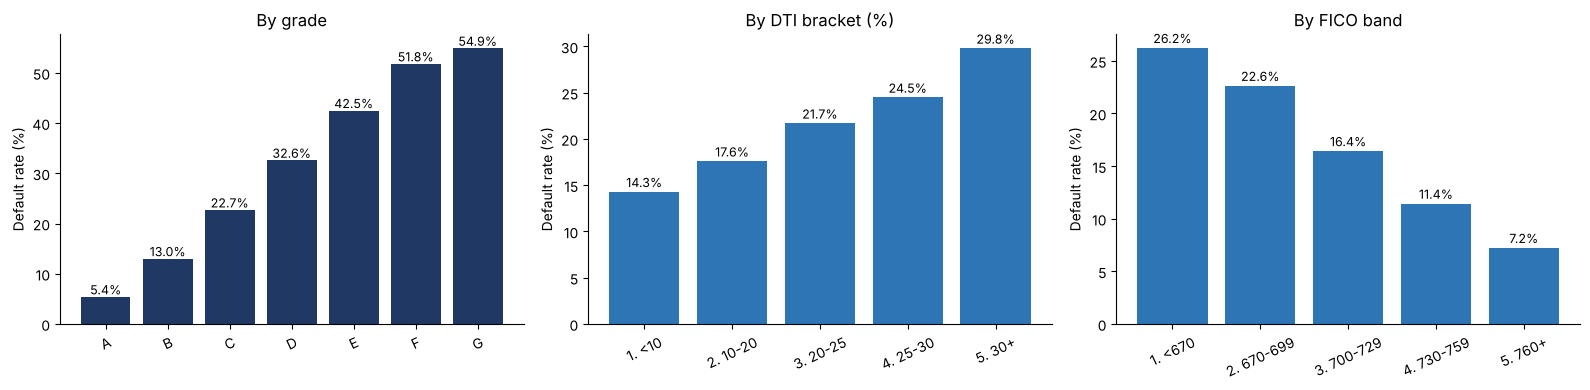

In [11]:
def plot_bar(ax, df, title, color):
    ax.bar(df.segment.astype(str), df.default_rate_pct, color=color)
    for i, v in enumerate(df.default_rate_pct):
        ax.text(i, v + 0.5, f"{v:.1f}%", ha="center", fontsize=9)
    ax.set_title(title); ax.set_ylabel("Default rate (%)")
    ax.spines[["top","right"]].set_visible(False)
    ax.tick_params(axis="x", labelrotation=25)

fig, axs = plt.subplots(1, 3, figsize=(16, 4))
plot_bar(axs[0], by_grade, "By grade", "#1F3864")
plot_bar(axs[1], by_dti,  "By DTI bracket (%)", "#2E75B6")
plot_bar(axs[2], by_fico, "By FICO band", "#2E75B6")
plt.tight_layout(); plt.show()

### Grade × DTI heatmap (shows why we combine the two)

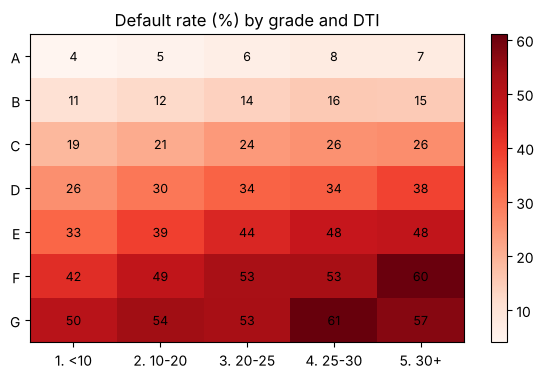

In [12]:
d = q("SELECT * FROM loans")                       # pull cleaned table into pandas
heat = d.pivot_table(index="grade", columns="dti_bracket", values="default_flag", aggfunc="mean") * 100

fig, ax = plt.subplots(figsize=(7, 4))
im = ax.imshow(heat.values, cmap="Reds", aspect="auto")
ax.set_xticks(range(heat.shape[1]), heat.columns); ax.set_yticks(range(heat.shape[0]), heat.index)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        ax.text(j, i, f"{heat.values[i, j]:.0f}", ha="center", va="center", fontsize=9)
ax.set_title("Default rate (%) by grade and DTI"); plt.colorbar(im); plt.show()

## 6. Risk flag rule + out-of-sample test
**Rule:** flag a loan if **grade is E, F or G**, OR **grade is C or D and DTI ≥ 25%**.
Built by studying **Apr–Aug 2015 (train)** and checked on **Sep–Dec 2015 (test)** loans it never saw. Term is excluded (see caveat above).

In [13]:
d["period"] = np.where(d.issue_dt >= "2015-09-01", "test", "train")

def risk_flag(df):
    """True for loans the rule would flag."""
    return df.grade.isin(["E","F","G"]) | (df.grade.isin(["C","D"]) & (df.dti >= 25))

def evaluate(df, flag):
    """Default rate and return for flagged vs approved loans."""
    out = {}
    for name, g in (("flagged", df[flag]), ("approved", df[~flag])):
        out[name] = {"loans": len(g), "defaults": int(g.default_flag.sum()),
                     "default_rate_%": 100 * g.default_flag.mean(),
                     "return_%": 100 * g.net_pnl.sum() / g.funded_amnt.sum()}
    res = pd.DataFrame(out).T
    res[["loans","defaults"]] = res[["loans","defaults"]].astype(int)
    return res

d["flag"] = risk_flag(d)
results = {p: evaluate(g, g.flag) for p, g in d.groupby("period")}
print("TRAIN (Apr-Aug)"); display(results["train"])
print("TEST  (Sep-Dec, out-of-sample)"); display(results["test"])

TRAIN (Apr-Aug)


,loans,defaults,default_rate_%,return_%
flagged,34421,12557,36.48,-1.94
approved,109195,16661,15.26,5.95


TEST  (Sep-Dec, out-of-sample)


,loans,defaults,default_rate_%,return_%
flagged,30629,11338,37.02,-5.04
approved,109408,16706,15.27,4.94


## 7. Back-test: what if we had declined every flagged loan? (test period)

In [14]:
t = d[d.period == "test"]
flagged, approved = t[t.flag], t[~t.flag]

backtest = {
 "Loans in test period":            len(t),
 "Loans declined (flagged)":        len(flagged),
 "% of loans declined":             100 * len(flagged) / len(t),
 "Defaults before rule":            int(t.default_flag.sum()),
 "Defaults avoided":                int(flagged.default_flag.sum()),
 "% of all defaults avoided":       100 * flagged.default_flag.sum() / t.default_flag.sum(),
 "Good loans declined (the cost)":  int((1 - flagged.default_flag).sum()),
 "Default rate before (%)":         100 * t.default_flag.mean(),
 "Default rate after (%)":          100 * approved.default_flag.mean(),
 "Fall in default rate (pp)":       100 * (t.default_flag.mean() - approved.default_flag.mean()),
 "Return on flagged loans (%)":     100 * flagged.net_pnl.sum() / flagged.funded_amnt.sum(),
 "Return on approved loans (%)":    100 * approved.net_pnl.sum() / approved.funded_amnt.sum(),
}
pd.Series(backtest).map(lambda v: f"{v:,.1f}" if isinstance(v, float) else f"{v:,}").to_frame("value")

,value
Loans in test period,"140,037.0"
Loans declined (flagged),"30,629.0"
% of loans declined,21.9
Defaults before rule,"28,044.0"
Defaults avoided,"11,338.0"
% of all defaults avoided,40.4
Good loans declined (the cost),"19,291.0"
Default rate before (%),20.0
Default rate after (%),15.3
Fall in default rate (pp),4.8


### Same back-test written in SQL (cross-check)

In [15]:
con.executescript("""
DROP VIEW IF EXISTS flagged;
CREATE VIEW flagged AS
SELECT *,
  CASE WHEN grade IN ('E','F','G') OR (grade IN ('C','D') AND dti >= 25) THEN 1 ELSE 0 END AS risk_flag,
  CASE WHEN issue_dt >= '2015-09-01' THEN 'test' ELSE 'train' END AS period
FROM loans;""")

q("""
SELECT period, risk_flag, COUNT(*) AS loans, SUM(default_flag) AS defaults,
       ROUND(100.0*AVG(default_flag),1) AS default_rate_pct,
       ROUND(100.0*SUM(net_pnl)/SUM(funded_amnt),1) AS return_pct
FROM flagged GROUP BY period, risk_flag ORDER BY period, risk_flag""")

,period,risk_flag,loans,defaults,default_rate_pct,return_pct
0,test,0,109408,16706,15.30,4.90
1,test,1,30629,11338,37.00,-5.00
2,train,0,109195,16661,15.30,5.90
3,train,1,34421,12557,36.50,-1.90


## 8. Why these thresholds? (rule comparison on the test period)
All four rules perform within a few points of each other. Be honest about it in the interview:
*"I compared a few simple rules. A plain Grade D–G rule did marginally better on this test, but I kept the grade + DTI rule because DTI is the affordability measure banks actually use, and it adds a second risk driver beyond the lender's own grade."*

In [16]:
rules = {
 "Grade D-G only":                 lambda x: x.grade.isin(list("DEFG")),
 "Grade D-G, or C with DTI>=25":   lambda x: x.grade.isin(list("DEFG")) | ((x.grade == "C") & (x.dti >= 25)),
 "Grade E-G, or C/D with DTI>=25 (chosen)": lambda x: x.grade.isin(list("EFG")) | (x.grade.isin(["C","D"]) & (x.dti >= 25)),
 "Chosen rule + B with DTI>=30":   lambda x: x.grade.isin(list("EFG")) | (x.grade.isin(["C","D"]) & (x.dti >= 25)) | ((x.grade == "B") & (x.dti >= 30)),
}
rows = []
for name, fn in rules.items():
    f = fn(t)
    rows.append({"rule": name, "% declined": 100*f.mean(),
                 "flagged default rate %": 100*t[f].default_flag.mean(),
                 "% defaults avoided": 100*t[f].default_flag.sum()/t.default_flag.sum(),
                 "good loans lost": int((1 - t[f].default_flag).sum()),
                 "return on flagged %": 100*t[f].net_pnl.sum()/t[f].funded_amnt.sum()})
pd.DataFrame(rows).set_index("rule")

,% declined,flagged default rate %,% defaults avoided,good loans lost,return on flagged %
rule,,,,,
Grade D-G only,22.01,38.56,42.39,18940,-5.12
"Grade D-G, or C with DTI>=25",30.04,35.38,53.07,27186,-3.72
"Grade E-G, or C/D with DTI>=25 (chosen)",21.87,37.02,40.43,19291,-5.04
Chosen rule + B with DTI>=30,24.49,34.76,42.51,22372,-4.15


## 9. Check: do the notebook numbers match the resume?

In [17]:
def top(df, seg): return float(df.loc[df.segment == seg, "default_rate_pct"].iloc[0])

checks = {
 "Resolved loans analysed (K, rounded)":     (round(base.loans[0] / 1000),             284),
 "Overall default rate %":          (round(float(base.default_rate_pct[0]), 1), 20.2),
 "Grade A default %":               (top(by_grade, "A"),                       5.4),
 "Grade G default %":               (top(by_grade, "G"),                       54.9),
 "DTI 30%+ default %":              (top(by_dti, "5. 30+"),                    29.8),
 "DTI <10 default %":               (top(by_dti, "1. <10"),                    14.3),
 "FICO <670 default %":             (top(by_fico, "1. <670"),                  26.2),
 "FICO 760+ default %":             (top(by_fico, "5. 760+"),                  7.2),
 "% loans flagged (test)":          (round(backtest["% of loans declined"], 1), 21.9),
 "Flagged default rate % (test)":   (round(results["test"].loc["flagged","default_rate_%"], 1), 37.0),
 "Approved default rate % (test)":  (round(results["test"].loc["approved","default_rate_%"], 1), 15.3),
 "% defaults avoided":              (round(backtest["% of all defaults avoided"], 1), 40.4),
 "Default rate before %":           (round(backtest["Default rate before (%)"], 1), 20.0),
 "Default rate after %":            (round(backtest["Default rate after (%)"], 1), 15.3),
 "Return flagged %":                (round(backtest["Return on flagged loans (%)"], 1), -5.0),
 "Return approved %":              (round(backtest["Return on approved loans (%)"], 1), 4.9),
}
tbl = pd.DataFrame(checks, index=["notebook", "resume"]).T
tbl["match"] = np.where(tbl.notebook == tbl.resume, "OK", "CHECK")
display(tbl)
print("All resume numbers reproduced." if (tbl.match == "OK").all() else "Some numbers differ: use YOUR notebook values on the resume.")

,notebook,resume,match
"Resolved loans analysed (K, rounded)",284.00,284.00,OK
Overall default rate %,20.20,20.20,OK
Grade A default %,5.40,5.40,OK
Grade G default %,54.90,54.90,OK
DTI 30%+ default %,29.80,29.80,OK
DTI <10 default %,14.30,14.30,OK
FICO <670 default %,26.20,26.20,OK
FICO 760+ default %,7.20,7.20,OK
% loans flagged (test),21.90,21.90,OK
Flagged default rate % (test),37.00,37.00,OK


All resume numbers reproduced.


## 10. Interview cheat-sheet

### Functions / syntax to remember
| What | Code | Why |
|---|---|---|
| Read only needed columns | `pd.read_csv(f, usecols=COLS)` | Faster, less memory |
| Join many files | `pd.concat(frames, ignore_index=True)` | Stack 16 parts into one table |
| Find files | `glob.glob(folder + pattern)` | Pick up all `_1 … _16` parts |
| Parse dates | `pd.to_datetime(col, format="%b-%Y")` | `"Dec-2015"` → real date |
| Pull number from text | `col.str.extract(r"(\d+)").astype(int)` | `" 36 months"` → 36 |
| Pandas → SQL | `df.to_sql("table", con)` | Lets us run SQL on a DataFrame |
| SQL → pandas | `pd.read_sql(query, con)` | Query result as a DataFrame |
| Segment table | `groupby(col).agg(...)` / SQL `GROUP BY` | Default rate per group |
| Matching values | `col.isin(["E","F","G"])` / SQL `IN (...)` | Grade is any of these |
| Heatmap table | `df.pivot_table(index, columns, values, aggfunc="mean")` | Grade × DTI |
| Split train/test | `np.where(date >= "2015-09-01", "test", "train")` | Out-of-sample check |

### SQL to remember
- `CASE WHEN … THEN … ELSE … END` → makes bands and the 0/1 default flag
- `WHERE loan_status IN (…)` → keep resolved loans
- `AVG(default_flag)` → default rate
- `GROUP BY` + `COUNT(*)`, `SUM()` → segment tables
- `CREATE TABLE … AS SELECT` / `CREATE VIEW` → save cleaned data / the flag rule

### Likely questions (short answers)
- **Why only resolved loans?** Current loans have no final outcome, so counting them as good would understate defaults.
- **Why train/test?** To show the rule works on months it was not built on: flagged default rate stayed 37.0% vs 15.3% for the rest.
- **What does the rule cost?** It declines 19,291 loans that would have repaid. It removes 40.4% of defaults, and flagged loans lose money overall (−5.0% return).
- **Why not use loan term?** Many 2015 60-month loans are still open, which biases their default rate upward.
- **Limits?** One vintage (2015), one lender, back-test ignores funding costs. A bank could reprice instead of declining.
- **How would this apply at ICICI?** Same idea for retail loan approval: score by risk grade/bureau score and DTI, flag the high-risk segment, then decline, cap or reprice.